In [182]:
# Generic inputs for most ML tasks
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
# This is new
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.ensemble import RandomForestRegressor

pd.options.display.float_format = '{:,.2f}'.format

# setup interactive notebook mode
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

from IPython.display import display, HTML

In [183]:
# fetch data 

mco_syr_sw_data = pd.read_csv('flight_data\mco_syr_sw_20_21_22_23_new.csv')
mco_syr_jb_data = pd.read_csv('flight_data\mco_syr_jb_20_21_22_23.csv')
jfk_syr_jb_data = pd.read_csv('flight_data\jfk_syr_jb_20_21_22_23.csv')
jfk_syr_dl_data = pd.read_csv('flight_data\jfk_syr_dl_20_21_22_23.csv')
ord_syr_ua_data = pd.read_csv('flight_data\ord_syr_ua_20_21_22_23.csv')
ord_syr_aa_data = pd.read_csv('flight_data\ord_syr_aa_20_21_22_23.csv')
# mco_syr_sw_data.head()
# mco_syr_jb_data.head()
# jfk_syr_jb_data.head()
# jfk_syr_end_data.head()
# ord_syr_ua_data.head()
# ord_syr_aa_data.head()

In [184]:
dfs = [ord_syr_aa_data,ord_syr_ua_data,jfk_syr_dl_data,jfk_syr_jb_data,mco_syr_jb_data,mco_syr_sw_data]
main_data = pd.concat(dfs,axis = 0)
main_data.head()
len(main_data)

,Unnamed: 0,Carrier_Code,Date,Flight_Number,Tail_Number,Destination_Airport,Scheduled departure time,Actual departure time,Scheduled elapsed time (Minutes),Actual elapsed time (Minutes),...,Wheels-on Time,Taxi-In time (Minutes),arr_Delay_Carrier,arr_Delay_Weather,arr_Delay_National_Aviation_System,arr_Delay_Security,arr_Delay_Late_Aircraft_Arrival,arr_hour,arr_day,arr_year
0,0,MQ,2020-01-04,"3,580.00",N240NN,SYR,7:55,8:21,112.00,87.00,...,10:43,5.00,0.00,0.00,0.00,0.00,0.00,10,5,2020
1,1,MQ,2020-01-11,"3,946.00",N247NN,SYR,15:00,15:09,108.00,132.00,...,18:13,8.00,9.00,0.00,24.00,0.00,0.00,17,5,2020
2,2,MQ,2020-01-18,"3,946.00",N265NN,SYR,15:00,16:27,108.00,147.00,...,19:45,9.00,0.00,4.00,39.00,0.00,83.00,17,5,2020
3,3,MQ,2020-01-25,"3,946.00",N281NN,SYR,15:00,14:55,108.00,126.00,...,17:56,5.00,0.00,0.00,0.00,0.00,0.00,17,5,2020
4,4,MQ,2020-02-01,"3,946.00",N283NN,SYR,15:00,14:57,108.00,99.00,...,17:32,4.00,0.00,0.00,0.00,0.00,0.00,17,5,2020


6914

In [136]:
main_data.dtypes



Unnamed: 0                              int64
Carrier_Code                           object
Date                                   object
Flight_Number                         float64
Tail_Number                            object
Destination_Airport                    object
Scheduled departure time               object
Actual departure time                  object
Scheduled elapsed time (Minutes)      float64
Actual elapsed time (Minutes)         float64
Departure delay (Minutes)             float64
Wheels-off time                        object
Taxi-Out time (Minutes)               float64
dep_Delay_Carrier                     float64
dep_Delay_Weather                     float64
dep_Delay_National_Aviation_System    float64
dep_Delay_Security                    float64
dep_Delay_Late_Aircraft_Arrival       float64
dep_hour                                int64
dep_day                                 int64
dep_year                                int64
dep_order                         

In [137]:
sub_data = main_data.drop(columns = ['Unnamed: 0','Destination_Airport','Actual departure time','Scheduled elapsed time (Minutes)','Actual elapsed time (Minutes)',
                         'Wheels-off time','Taxi-Out time (Minutes)','dep_Delay_Carrier',
                         'dep_Delay_Weather','dep_Delay_National_Aviation_System','dep_Delay_Security','dep_Delay_Late_Aircraft_Arrival',
                         'dep_year','Actual Arrival Time','Wheels-on Time','Taxi-In time (Minutes)','arr_Delay_Carrier','arr_Delay_Weather',
                         'arr_Delay_National_Aviation_System','arr_Delay_Security','arr_Delay_Late_Aircraft_Arrival','arr_year'])

In [138]:
sub_data.dtypes


Carrier_Code                  object
Date                          object
Flight_Number                float64
Tail_Number                   object
Scheduled departure time      object
Departure delay (Minutes)    float64
dep_hour                       int64
dep_day                        int64
dep_order                     object
Origin_Airport                object
Scheduled Arrival Time        object
Arrival Delay (Minutes)      float64
arr_hour                       int64
arr_day                        int64
dtype: object

In [139]:
sub_data.head()

,Carrier_Code,Date,Flight_Number,Tail_Number,Scheduled departure time,Departure delay (Minutes),dep_hour,dep_day,dep_order,Origin_Airport,Scheduled Arrival Time,Arrival Delay (Minutes),arr_hour,arr_day
0,MQ,2020-01-04,"3,580.00",N240NN,7:55,26.00,7,5,latter,ORD,10:47,1.00,10,5
1,MQ,2020-01-11,"3,946.00",N247NN,15:00,9.00,15,5,latter,ORD,17:48,33.00,17,5
2,MQ,2020-01-18,"3,946.00",N265NN,15:00,87.00,15,5,latter,ORD,17:48,126.00,17,5
3,MQ,2020-01-25,"3,946.00",N281NN,15:00,-5.00,15,5,latter,ORD,17:48,13.00,17,5
4,MQ,2020-02-01,"3,946.00",N283NN,15:00,-3.00,15,5,latter,ORD,17:48,-12.00,17,5


In [140]:
sub_data['dep_min'] = sub_data['Scheduled departure time'].str.split(":").str[1].astype('int64')
# def round_to_nearest_quarter(minute):
#     if 0 <= minute < 14:
#         return 0
#     elif 15 <= minute < 29:
#         return 15
#     elif 30 <= minute < 44:
#         return 30
#     else:
#         return 45
sub_data['Date'] = pd.to_datetime( sub_data['Date'],format ="%Y-%m-%d")
sub_data['Date'] = sub_data['Date'].dt.strftime('%m/%d/%Y')
# sub_data['dep_minutes'] = 0
# sub_data['dep_minutes'] = sub_data['dep_minutes'].astype('object')
sub_data['dep_hours'] = sub_data['dep_hour'].astype('object')
sub_data['dep_min'] = sub_data['dep_min'].astype('object')
sub_data['arr_min'] = main_data['Scheduled Arrival Time'].str.split(":").str[1].astype('int64')
# sub_data['arr_minutes'] = 0
# sub_data['arr_minutes'] = sub_data['arr_minutes'].astype('object')
sub_data['arr_hours'] = sub_data['arr_hour'].astype('object')
sub_data['arr_min'] = sub_data['arr_min'].astype('object')
sub_data['Flight_Number'] = main_data['Flight_Number'].astype('object')
sub_data['dep_hour'] = main_data['dep_hour'].astype('object')
sub_data['dep_day'] = main_data['dep_day'].astype('object')
sub_data['arr_hour'] = main_data['arr_hour'].astype('object')
sub_data['arr_day'] = main_data['arr_day'].astype('object')
conditions = [
    (sub_data['Arrival Delay (Minutes)'] > 5),
    (sub_data['Arrival Delay (Minutes)'] >=-5) & (sub_data['Arrival Delay (Minutes)'] <= 5),
    (sub_data['Arrival Delay (Minutes)'] < -5)
]
choices = [2,1,0]
sub_data['arr_status'] = np.select(conditions, choices)
sub_data.dtypes
sub_data.head()

Carrier_Code                  object
Date                          object
Flight_Number                 object
Tail_Number                   object
Scheduled departure time      object
Departure delay (Minutes)    float64
dep_hour                      object
dep_day                       object
dep_order                     object
Origin_Airport                object
Scheduled Arrival Time        object
Arrival Delay (Minutes)      float64
arr_hour                      object
arr_day                       object
dep_min                       object
dep_hours                     object
arr_min                       object
arr_hours                     object
arr_status                     int32
dtype: object

,Carrier_Code,Date,Flight_Number,Tail_Number,Scheduled departure time,Departure delay (Minutes),dep_hour,dep_day,dep_order,Origin_Airport,Scheduled Arrival Time,Arrival Delay (Minutes),arr_hour,arr_day,dep_min,dep_hours,arr_min,arr_hours,arr_status
0,MQ,01/04/2020,"3,580.00",N240NN,7:55,26.00,7,5,latter,ORD,10:47,1.00,10,5,55,7,47,10,1
1,MQ,01/11/2020,"3,946.00",N247NN,15:00,9.00,15,5,latter,ORD,17:48,33.00,17,5,0,15,48,17,2
2,MQ,01/18/2020,"3,946.00",N265NN,15:00,87.00,15,5,latter,ORD,17:48,126.00,17,5,0,15,48,17,2
3,MQ,01/25/2020,"3,946.00",N281NN,15:00,-5.00,15,5,latter,ORD,17:48,13.00,17,5,0,15,48,17,2
4,MQ,02/01/2020,"3,946.00",N283NN,15:00,-3.00,15,5,latter,ORD,17:48,-12.00,17,5,0,15,48,17,0


In [141]:
sub_data.to_csv('sub_data.csv', index=False)

In [142]:
# Read and process weather data files for each airport
jfk_weather_data = pd.read_csv('weather_data/JFK_weather_data_hourly_processed.csv')
syr_weather_data = pd.read_csv('weather_data/SYR_weather_data_hourly_processed.csv')
ord_weather_data = pd.read_csv('weather_data/ORD_weather_data_hourly_processed.csv')
mco_weather_data = pd.read_csv('weather_data/MCO_weather_data_hourly_processed.csv')

# Combine weather data for all airports
weather_dfs = [jfk_weather_data, ord_weather_data, mco_weather_data]
weather_data = pd.concat(weather_dfs, axis=0)
weather_data['dep_hours'] = weather_data['dep_hours'].astype('object')
syr_weather_data['arr_hours'] = syr_weather_data['arr_hours'].astype('object')
weather_data.head()
syr_weather_data.head()
weather_data.dtypes
syr_weather_data.dtypes




,dep_azimuth,dep_clouds,dep_dewpt,dep_elev_angle,dep_h_angle,dep_precip,dep_pres,dep_revision_status,dep_rh,dep_snow,dep_temp,dep_vis,dep_weather.description,dep_weather.code,dep_wind_dir,dep_wind_gust_spd,dep_wind_spd,Date,dep_hours,Origin_Airport
0,261.20,100.00,3.80,-26.20,NaN,0.00,"1,002.00",final,88.00,0.00,5.60,16.00,Overcast clouds,804,220.00,6.00,3.60,12/31/2019,19,JFK
1,270.50,100.00,3.90,-37.50,NaN,0.25,"1,003.00",final,85.00,0.00,6.30,16.00,Overcast clouds,804,220.00,6.80,5.37,12/31/2019,20,JFK
2,281.40,100.00,3.70,-48.80,NaN,0.00,"1,003.00",final,82.00,0.00,6.50,16.00,Overcast clouds,804,255.00,8.00,7.45,12/31/2019,21,JFK
3,296.30,100.00,1.60,-59.60,NaN,0.00,"1,002.00",final,73.00,0.00,6.10,16.00,Overcast clouds,804,270.00,9.30,6.70,12/31/2019,22,JFK
4,320.80,100.00,0.70,-68.60,NaN,0.00,"1,003.00",final,69.00,0.00,6.00,16.00,Overcast clouds,804,270.00,10.40,7.45,12/31/2019,23,JFK


,arr_azimuth,arr_clouds,arr_dewpt,arr_elev_angle,arr_h_angle,arr_precip,arr_pres,arr_revision_status,arr_rh,arr_snow,arr_temp,arr_vis,arr_weather.description,arr_weather.code,arr_wind_dir,arr_wind_gust_spd,arr_wind_spd,Date,arr_hours
0,260.90,100.00,-2.30,-24.90,NaN,0.00,987.00,final,78.00,0.00,1.10,14.00,Overcast clouds,804,240.00,9.60,4.59,12/31/2019,19
1,270.70,100.00,-3.00,-35.80,NaN,0.00,987.00,final,77.00,0.00,0.60,16.00,Overcast clouds,804,240.00,9.60,4.59,12/31/2019,20
2,282.10,100.00,-4.00,-46.60,NaN,0.00,986.00,final,71.00,0.00,0.60,16.00,Overcast clouds,804,240.00,10.40,5.70,12/31/2019,21
3,297.00,100.00,-4.40,-56.90,NaN,0.00,987.00,final,69.00,0.00,0.60,16.00,Overcast clouds,804,250.00,10.40,6.20,12/31/2019,22
4,319.80,100.00,-4.40,-65.60,NaN,0.00,986.00,final,69.00,0.00,0.60,14.00,Overcast clouds,804,250.00,10.80,6.20,12/31/2019,23


dep_azimuth                float64
dep_clouds                 float64
dep_dewpt                  float64
dep_elev_angle             float64
dep_h_angle                float64
dep_precip                 float64
dep_pres                   float64
dep_revision_status         object
dep_rh                     float64
dep_snow                   float64
dep_temp                   float64
dep_vis                    float64
dep_weather.description     object
dep_weather.code             int64
dep_wind_dir               float64
dep_wind_gust_spd          float64
dep_wind_spd               float64
Date                        object
dep_hours                   object
Origin_Airport              object
dtype: object

arr_azimuth                float64
arr_clouds                 float64
arr_dewpt                  float64
arr_elev_angle             float64
arr_h_angle                float64
arr_precip                 float64
arr_pres                   float64
arr_revision_status         object
arr_rh                     float64
arr_snow                   float64
arr_temp                   float64
arr_vis                    float64
arr_weather.description     object
arr_weather.code             int64
arr_wind_dir               float64
arr_wind_gust_spd          float64
arr_wind_spd               float64
Date                        object
arr_hours                   object
dtype: object

In [143]:
# Define merging logic based on airport code
sub_data = pd.merge(sub_data, syr_weather_data, how='left', on=['Date', 'arr_hours'])
sub_data.head()



,Carrier_Code,Date,Flight_Number,Tail_Number,Scheduled departure time,Departure delay (Minutes),dep_hour,dep_day,dep_order,Origin_Airport,...,arr_revision_status,arr_rh,arr_snow,arr_temp,arr_vis,arr_weather.description,arr_weather.code,arr_wind_dir,arr_wind_gust_spd,arr_wind_spd
0,MQ,01/04/2020,"3,580.00",N240NN,7:55,26.00,7,5,latter,ORD,...,final,92.00,0.00,2.80,6.00,Light rain,500,350.00,5.09,5.09
1,MQ,01/11/2020,"3,946.00",N247NN,15:00,9.00,15,5,latter,ORD,...,final,83.00,0.00,15.00,16.00,Light rain,500,150.00,11.50,2.10
2,MQ,01/18/2020,"3,946.00",N265NN,15:00,87.00,15,5,latter,ORD,...,final,84.00,20.00,-3.90,0.00,Light snow,600,110.00,9.80,4.09
3,MQ,01/25/2020,"3,946.00",N281NN,15:00,-5.00,15,5,latter,ORD,...,final,96.00,1.50,1.10,3.00,Sleet,611,110.00,2.60,2.60
4,MQ,02/01/2020,"3,946.00",N283NN,15:00,-3.00,15,5,latter,ORD,...,final,75.00,0.00,0.00,16.00,Overcast clouds,804,245.00,1.60,0.80


In [144]:
sub_data.isna().sum()

Carrier_Code                    0
Date                            0
Flight_Number                   0
Tail_Number                    74
Scheduled departure time        0
Departure delay (Minutes)       0
dep_hour                        0
dep_day                         0
dep_order                       0
Origin_Airport                  0
Scheduled Arrival Time          0
Arrival Delay (Minutes)         0
arr_hour                        0
arr_day                         0
dep_min                         0
dep_hours                       0
arr_min                         0
arr_hours                       0
arr_status                      0
arr_azimuth                     0
arr_clouds                      0
arr_dewpt                       0
arr_elev_angle                  0
arr_h_angle                  6914
arr_precip                      0
arr_pres                        0
arr_revision_status             0
arr_rh                          0
arr_snow                        0
arr_temp      

In [145]:
sub_data = pd.merge(sub_data, weather_data, how='left', on=['Origin_Airport', 'Date', 'dep_hours'])


sub_data.head()

,Carrier_Code,Date,Flight_Number,Tail_Number,Scheduled departure time,Departure delay (Minutes),dep_hour,dep_day,dep_order,Origin_Airport,...,dep_revision_status,dep_rh,dep_snow,dep_temp,dep_vis,dep_weather.description,dep_weather.code,dep_wind_dir,dep_wind_gust_spd,dep_wind_spd
0,MQ,01/04/2020,"3,580.00",N240NN,7:55,26.00,7,5,latter,ORD,...,final,88.00,0.00,-1.10,11.00,Overcast clouds,804,320.00,6.80,3.10
1,MQ,01/11/2020,"3,946.00",N247NN,15:00,9.00,15,5,latter,ORD,...,final,96.00,8.50,-0.60,2.00,Light snow,600,20.00,15.90,10.80
2,MQ,01/18/2020,"3,946.00",N265NN,15:00,87.00,15,5,latter,ORD,...,final,86.00,6.25,-4.80,14.00,Flurries,623,250.00,16.80,11.17
3,MQ,01/25/2020,"3,946.00",N281NN,15:00,-5.00,15,5,latter,ORD,...,final,92.00,4.00,0.80,6.00,Light snow,600,255.00,8.20,4.34
4,MQ,02/01/2020,"3,946.00",N283NN,15:00,-3.00,15,5,latter,ORD,...,final,73.00,0.00,2.40,16.00,Overcast clouds,804,255.00,10.40,5.37


In [146]:
sub_data.isna().sum()

Carrier_Code                    0
Date                            0
Flight_Number                   0
Tail_Number                    74
Scheduled departure time        0
Departure delay (Minutes)       0
dep_hour                        0
dep_day                         0
dep_order                       0
Origin_Airport                  0
Scheduled Arrival Time          0
Arrival Delay (Minutes)         0
arr_hour                        0
arr_day                         0
dep_min                         0
dep_hours                       0
arr_min                         0
arr_hours                       0
arr_status                      0
arr_azimuth                     0
arr_clouds                      0
arr_dewpt                       0
arr_elev_angle                  0
arr_h_angle                  6914
arr_precip                      0
arr_pres                        0
arr_revision_status             0
arr_rh                          0
arr_snow                        0
arr_temp      

In [147]:
sub_data.columns

Index(['Carrier_Code', 'Date', 'Flight_Number', 'Tail_Number',
       'Scheduled departure time', 'Departure delay (Minutes)', 'dep_hour',
       'dep_day', 'dep_order', 'Origin_Airport', 'Scheduled Arrival Time',
       'Arrival Delay (Minutes)', 'arr_hour', 'arr_day', 'dep_min',
       'dep_hours', 'arr_min', 'arr_hours', 'arr_status', 'arr_azimuth',
       'arr_clouds', 'arr_dewpt', 'arr_elev_angle', 'arr_h_angle',
       'arr_precip', 'arr_pres', 'arr_revision_status', 'arr_rh', 'arr_snow',
       'arr_temp', 'arr_vis', 'arr_weather.description', 'arr_weather.code',
       'arr_wind_dir', 'arr_wind_gust_spd', 'arr_wind_spd', 'dep_azimuth',
       'dep_clouds', 'dep_dewpt', 'dep_elev_angle', 'dep_h_angle',
       'dep_precip', 'dep_pres', 'dep_revision_status', 'dep_rh', 'dep_snow',
       'dep_temp', 'dep_vis', 'dep_weather.description', 'dep_weather.code',
       'dep_wind_dir', 'dep_wind_gust_spd', 'dep_wind_spd'],
      dtype='object')

In [148]:
sub_data.to_csv('merged_data.csv', index=False)


In [149]:
sub_data.rename(columns={'Arrival Delay (Minutes)':'arr_delay'}, inplace=True)


In [150]:
sub_data.drop(columns= ['Carrier_Code','Date','Flight_Number','Tail_Number','arr_azimuth',
                       'Scheduled departure time','Scheduled Arrival Time','dep_order', 
                        'arr_hours', 'dep_hours',
                        'arr_weather.description', 'dep_weather.description','arr_delay','Departure delay (Minutes)',
                       'arr_elev_angle','arr_h_angle','arr_revision_status',
                       'dep_elev_angle','dep_h_angle','dep_revision_status','dep_azimuth'],inplace = True)


In [151]:

sub_data.dtypes
sub_data.columns

sub_data.head()
sub_data.isna().sum()

dep_hour              object
dep_day               object
Origin_Airport        object
arr_hour              object
arr_day               object
dep_min               object
arr_min               object
arr_status             int32
arr_clouds           float64
arr_dewpt            float64
arr_precip           float64
arr_pres             float64
arr_rh               float64
arr_snow             float64
arr_temp             float64
arr_vis              float64
arr_weather.code       int64
arr_wind_dir         float64
arr_wind_gust_spd    float64
arr_wind_spd         float64
dep_clouds           float64
dep_dewpt            float64
dep_precip           float64
dep_pres             float64
dep_rh               float64
dep_snow             float64
dep_temp             float64
dep_vis              float64
dep_weather.code       int64
dep_wind_dir         float64
dep_wind_gust_spd    float64
dep_wind_spd         float64
dtype: object

Index(['dep_hour', 'dep_day', 'Origin_Airport', 'arr_hour', 'arr_day',
       'dep_min', 'arr_min', 'arr_status', 'arr_clouds', 'arr_dewpt',
       'arr_precip', 'arr_pres', 'arr_rh', 'arr_snow', 'arr_temp', 'arr_vis',
       'arr_weather.code', 'arr_wind_dir', 'arr_wind_gust_spd', 'arr_wind_spd',
       'dep_clouds', 'dep_dewpt', 'dep_precip', 'dep_pres', 'dep_rh',
       'dep_snow', 'dep_temp', 'dep_vis', 'dep_weather.code', 'dep_wind_dir',
       'dep_wind_gust_spd', 'dep_wind_spd'],
      dtype='object')

,dep_hour,dep_day,Origin_Airport,arr_hour,arr_day,dep_min,arr_min,arr_status,arr_clouds,arr_dewpt,...,dep_precip,dep_pres,dep_rh,dep_snow,dep_temp,dep_vis,dep_weather.code,dep_wind_dir,dep_wind_gust_spd,dep_wind_spd
0,7,5,ORD,10,5,55,47,1,100.00,1.60,...,0.00,989.00,88.00,0.00,-1.10,11.00,804,320.00,6.80,3.10
1,15,5,ORD,17,5,0,48,2,100.00,12.10,...,0.50,985.00,96.00,8.50,-0.60,2.00,600,20.00,15.90,10.80
2,15,5,ORD,17,5,0,48,2,100.00,-6.20,...,0.25,983.00,86.00,6.25,-4.80,14.00,623,250.00,16.80,11.17
3,15,5,ORD,17,5,0,48,2,100.00,0.50,...,0.50,985.00,92.00,4.00,0.80,6.00,600,255.00,8.20,4.34
4,15,5,ORD,17,5,0,48,0,100.00,-3.90,...,0.00,984.00,73.00,0.00,2.40,16.00,804,255.00,10.40,5.37


dep_hour             0
dep_day              0
Origin_Airport       0
arr_hour             0
arr_day              0
dep_min              0
arr_min              0
arr_status           0
arr_clouds           0
arr_dewpt            0
arr_precip           0
arr_pres             0
arr_rh               0
arr_snow             0
arr_temp             0
arr_vis              0
arr_weather.code     0
arr_wind_dir         0
arr_wind_gust_spd    0
arr_wind_spd         0
dep_clouds           0
dep_dewpt            0
dep_precip           0
dep_pres             0
dep_rh               0
dep_snow             0
dep_temp             0
dep_vis              0
dep_weather.code     0
dep_wind_dir         0
dep_wind_gust_spd    0
dep_wind_spd         0
dtype: int64

In [152]:
#sub_data.to_csv('merged_data.csv', index=False)


In [153]:
# define function to import viz libraries
import plotly
plotly.offline.init_notebook_mode(connected=True)
from plotly.graph_objs import *
from plotly import tools
import plotly.graph_objects as go
import seaborn as sns

Index(['dep_hour', 'dep_day', 'Origin_Airport', 'arr_hour', 'arr_day',
       'dep_min', 'arr_min', 'arr_status', 'arr_clouds', 'arr_dewpt',
       'arr_precip', 'arr_pres', 'arr_rh', 'arr_snow', 'arr_temp', 'arr_vis',
       'arr_weather.code', 'arr_wind_dir', 'arr_wind_gust_spd', 'arr_wind_spd',
       'dep_clouds', 'dep_dewpt', 'dep_precip', 'dep_pres', 'dep_rh',
       'dep_snow', 'dep_temp', 'dep_vis', 'dep_weather.code', 'dep_wind_dir',
       'dep_wind_gust_spd', 'dep_wind_spd'],
      dtype='object')


<Axes: >

dep_hour


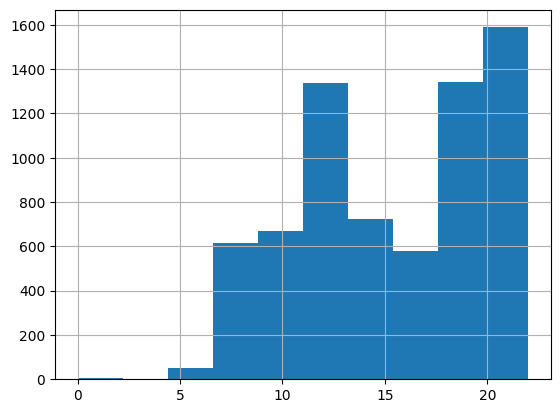

<Axes: >

dep_day


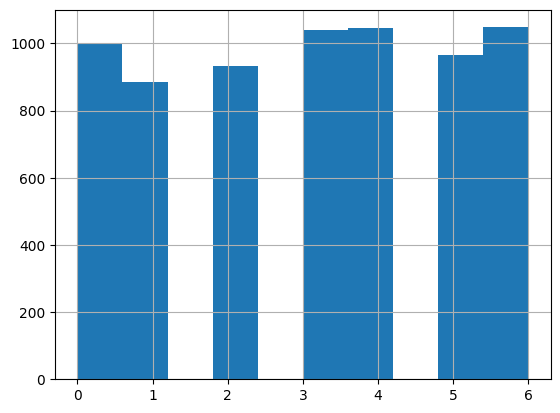

<Axes: >

Origin_Airport


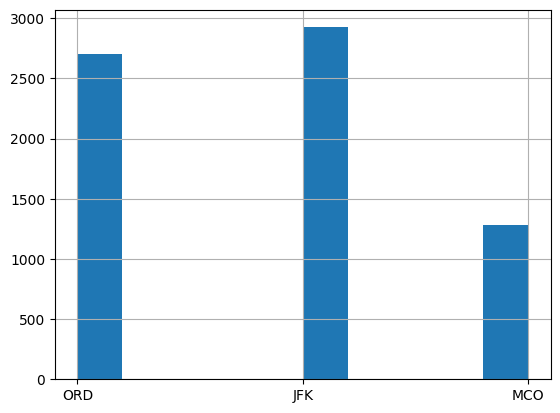

<Axes: >

arr_hour


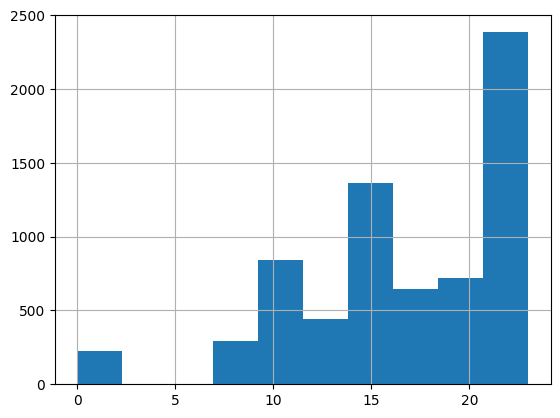

<Axes: >

arr_day


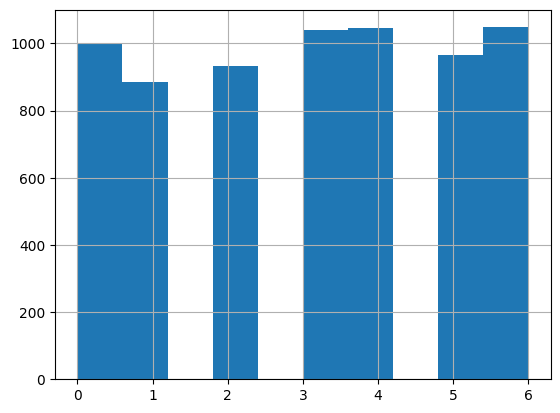

<Axes: >

dep_min


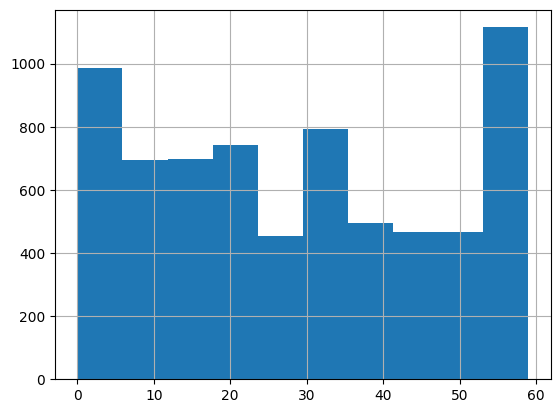

<Axes: >

arr_min


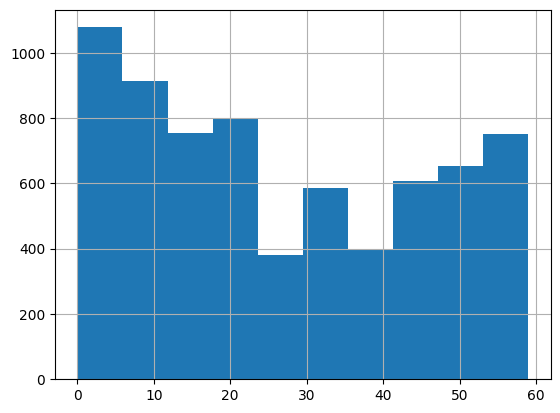

<Axes: >

arr_status


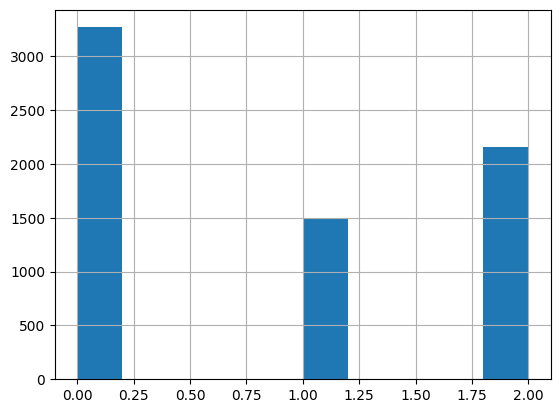

<Axes: >

arr_clouds


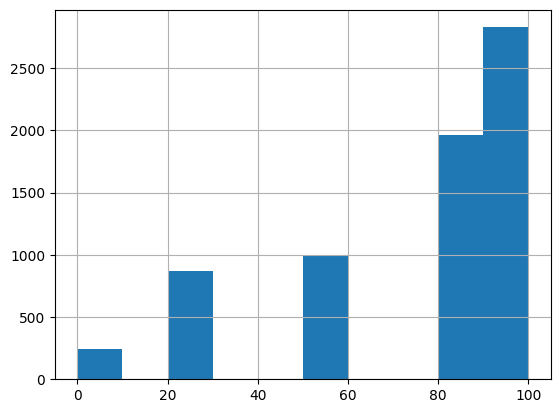

<Axes: >

arr_dewpt


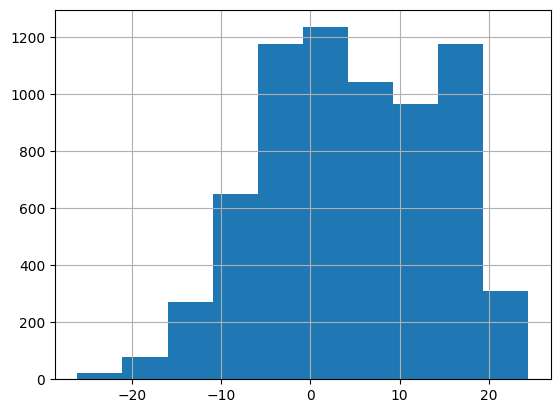

<Axes: >

arr_precip


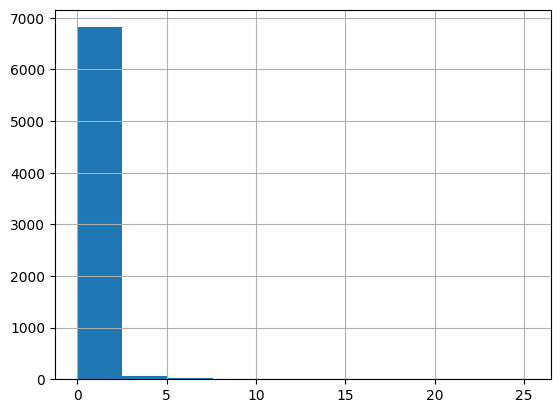

<Axes: >

arr_pres


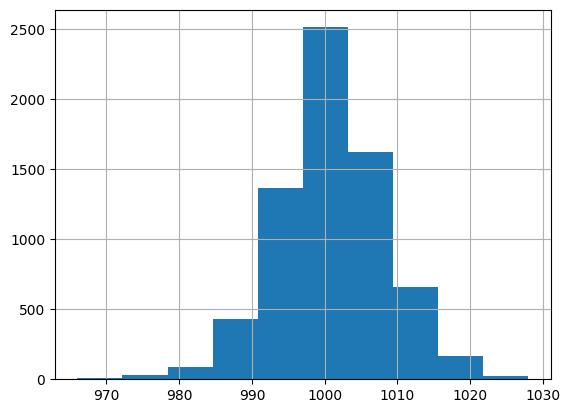

<Axes: >

arr_rh


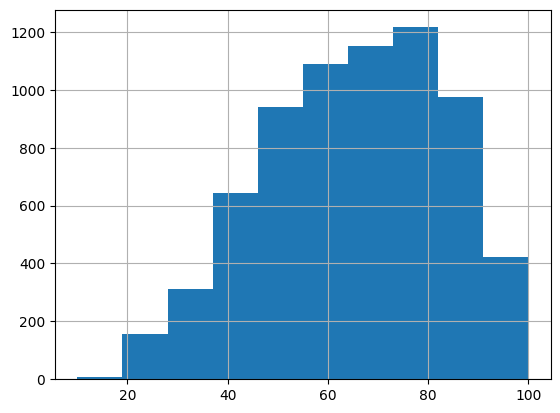

<Axes: >

arr_snow


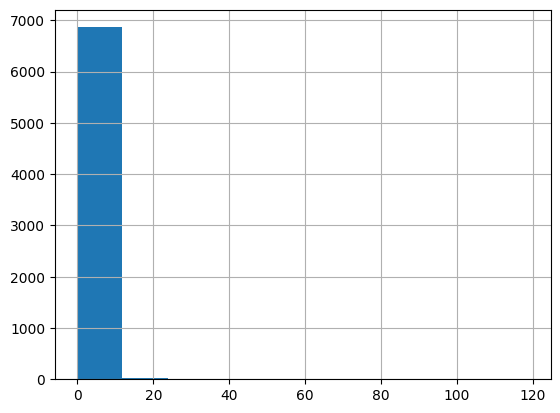

<Axes: >

arr_temp


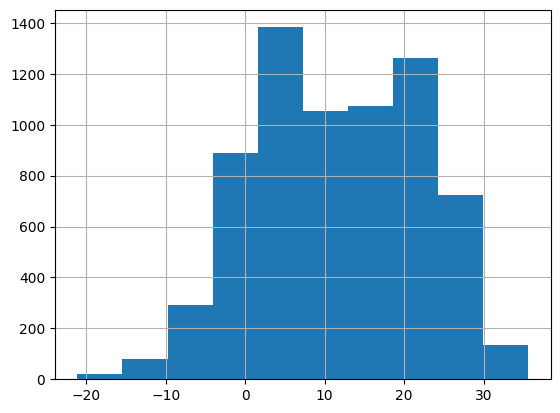

<Axes: >

arr_vis


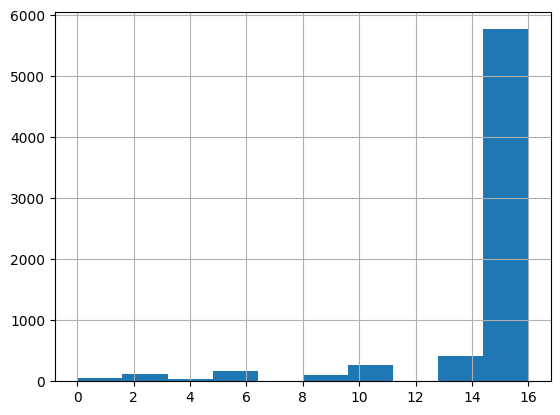

<Axes: >

arr_weather.code


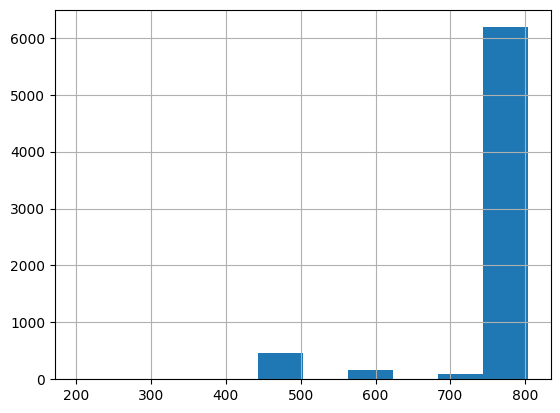

<Axes: >

arr_wind_dir


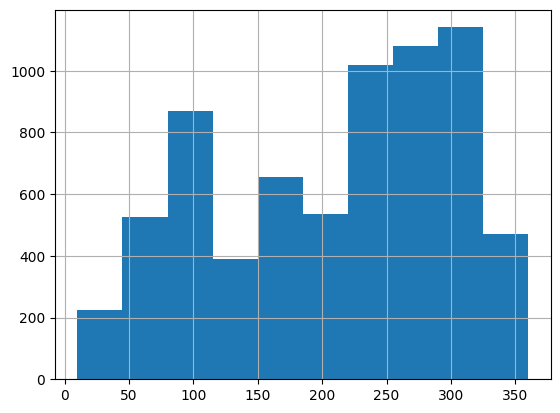

<Axes: >

arr_wind_gust_spd


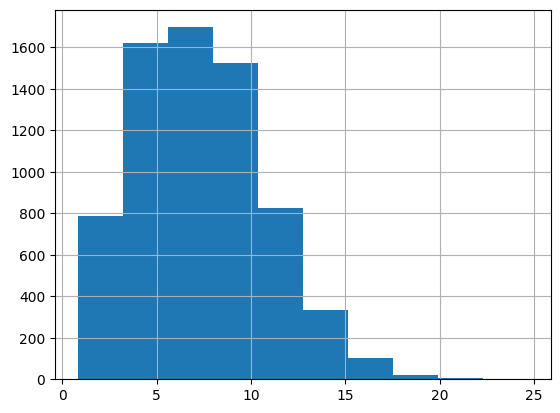

<Axes: >

arr_wind_spd


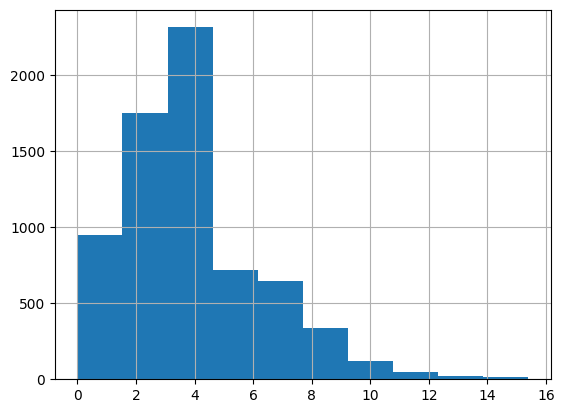

<Axes: >

dep_clouds


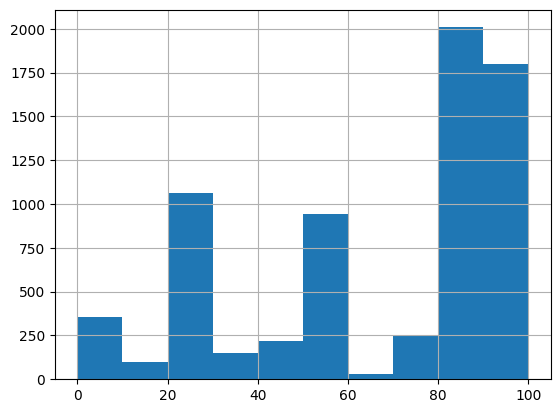

<Axes: >

dep_dewpt


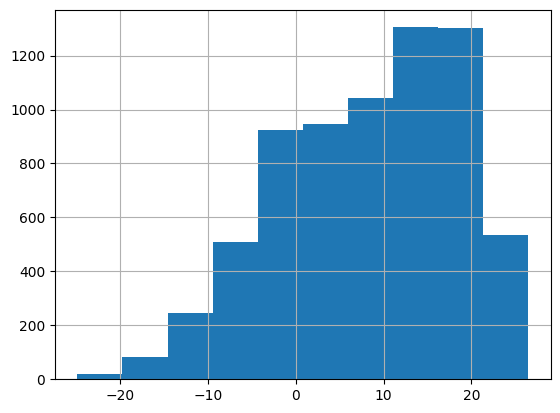

<Axes: >

dep_precip


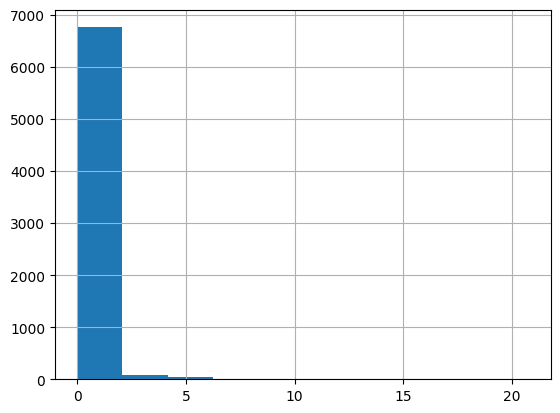

<Axes: >

dep_pres


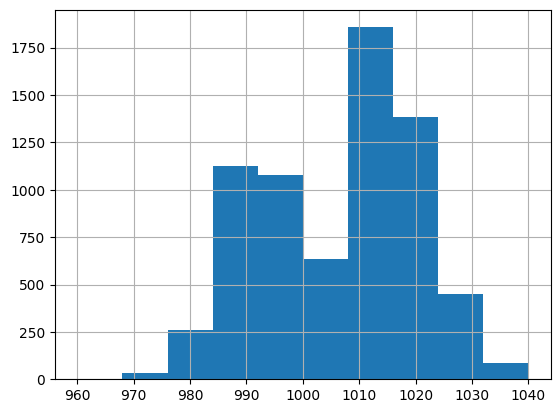

<Axes: >

dep_rh


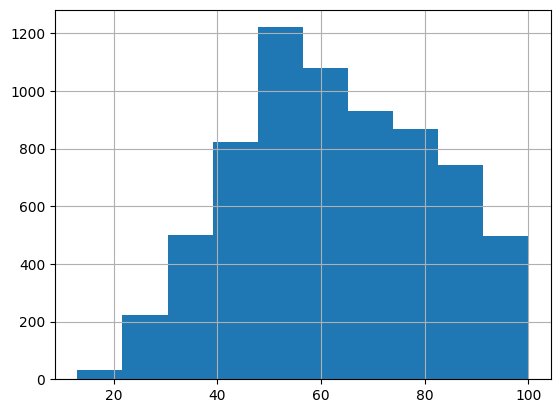

<Axes: >

dep_snow


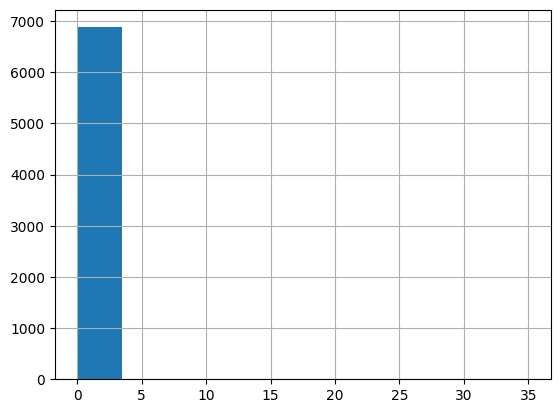

<Axes: >

dep_temp


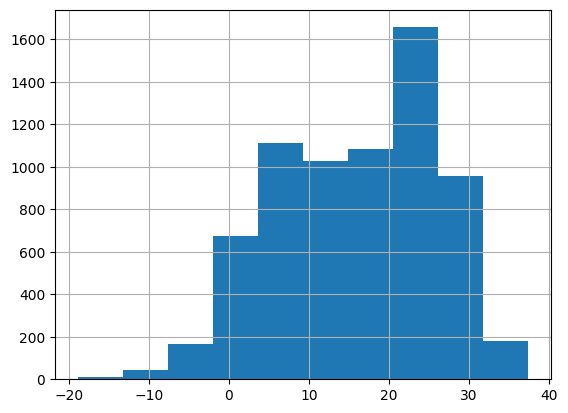

<Axes: >

dep_vis


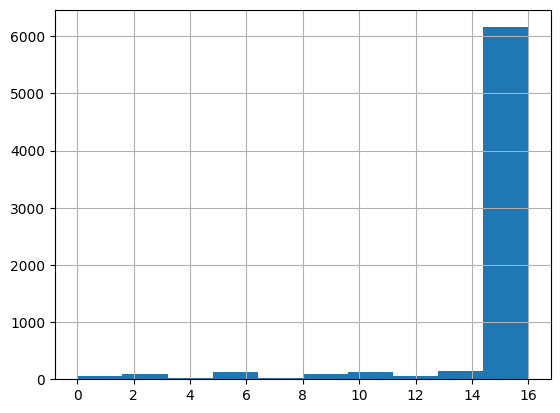

<Axes: >

dep_weather.code


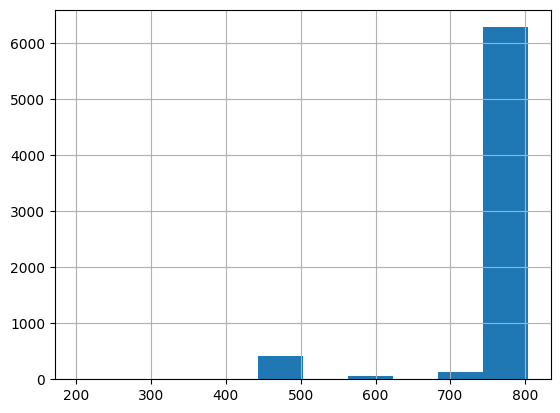

<Axes: >

dep_wind_dir


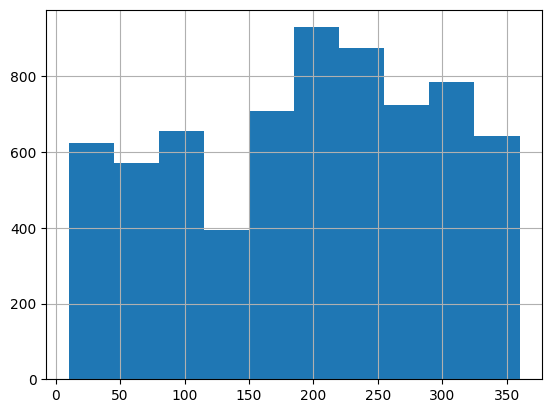

<Axes: >

dep_wind_gust_spd


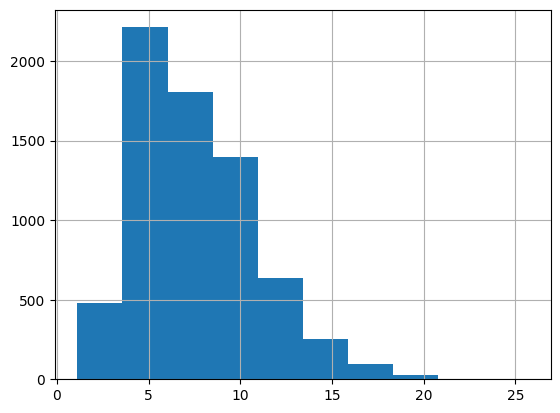

<Axes: >

dep_wind_spd


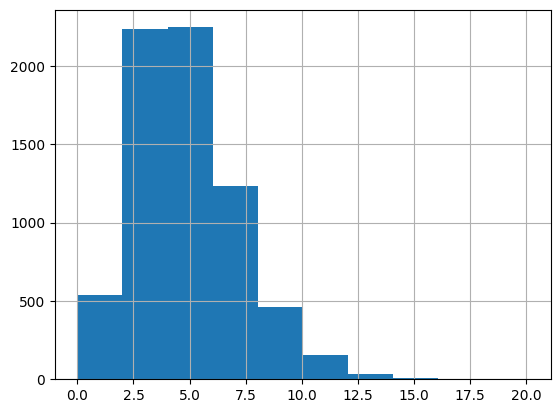

In [154]:
cols = sub_data.columns
print(cols)
for col in cols: 
    sub_data[col].hist()
    print(col)
    plt.show()

In [155]:
import plotly.express as px

In [156]:
sub_data.columns

Index(['dep_hour', 'dep_day', 'Origin_Airport', 'arr_hour', 'arr_day',
       'dep_min', 'arr_min', 'arr_status', 'arr_clouds', 'arr_dewpt',
       'arr_precip', 'arr_pres', 'arr_rh', 'arr_snow', 'arr_temp', 'arr_vis',
       'arr_weather.code', 'arr_wind_dir', 'arr_wind_gust_spd', 'arr_wind_spd',
       'dep_clouds', 'dep_dewpt', 'dep_precip', 'dep_pres', 'dep_rh',
       'dep_snow', 'dep_temp', 'dep_vis', 'dep_weather.code', 'dep_wind_dir',
       'dep_wind_gust_spd', 'dep_wind_spd'],
      dtype='object')

In [157]:
#for co in sub_data.columns:
fig = px.scatter(sub_data, y='dep_precip', x='arr_status', title='delay Over columns')
#fig.update_layout(height=1600, width=900, title_text="Stacked Subplots")
fig.show()

In [158]:
#sub_data['Carrier_Code'].unique()

In [159]:
# sub_data["Carrier_Code"] = np.where(sub_data["Carrier_Code"] == "MQ", "AA", sub_data["Carrier_Code"])
# sub_data["Carrier_Code"] = np.where(sub_data["Carrier_Code"] == "9E", "DL", sub_data["Carrier_Code"])

In [160]:
sub_data['Origin_Airport'].unique()

array(['ORD', 'JFK', 'MCO'], dtype=object)

In [161]:
su_data = sub_data
# su_data.head()
# sub_data.columns
su_data['dep_hour'] = pd.Categorical(su_data['dep_hour'], categories=[i for i in range(24)])
su_data['dep_day'] = pd.Categorical(su_data['dep_day'], categories=[i for i in range(7)])
su_data['dep_min'] = pd.Categorical(su_data['dep_min'], categories=[i for i in range(60)])
su_data['arr_hour'] = pd.Categorical(su_data['arr_hour'], categories=[i for i in range(24)])
su_data['arr_day'] = pd.Categorical(su_data['arr_day'], categories=[i for i in range(7)])
su_data['arr_min'] = pd.Categorical(su_data['arr_min'], categories=[i for i in range(60)])
#su_data['Carrier_Code'] = pd.Categorical(su_data['Carrier_Code'], categories=['AA', 'UA', 'DL', 'B6', 'WN'])
su_data['Origin_Airport'] = pd.Categorical(su_data['Origin_Airport'], categories=['ORD', 'JFK', 'MCO'])
su_data['arr_weather.code'] = pd.Categorical(su_data['arr_weather.code'], categories=[200,201,202,230,231,232,233,300,301,302,500,501,502,511,520,522,600,602,610,611,612,621,622,633,700,711,721,731,741,751,800,801,802,803,804,900])
su_data['dep_weather.code'] = pd.Categorical(su_data['dep_weather.code'], categories=[200,201,202,230,231,232,233,300,301,302,500,501,502,511,520,522,600,602,610,611,612,621,622,633,700,711,721,731,741,751,800,801,802,803,804,900])

#su_data.drop(columns=['arr_h_angle','dep_h_angle'],inplace = True)
su_data.columns

Index(['dep_hour', 'dep_day', 'Origin_Airport', 'arr_hour', 'arr_day',
       'dep_min', 'arr_min', 'arr_status', 'arr_clouds', 'arr_dewpt',
       'arr_precip', 'arr_pres', 'arr_rh', 'arr_snow', 'arr_temp', 'arr_vis',
       'arr_weather.code', 'arr_wind_dir', 'arr_wind_gust_spd', 'arr_wind_spd',
       'dep_clouds', 'dep_dewpt', 'dep_precip', 'dep_pres', 'dep_rh',
       'dep_snow', 'dep_temp', 'dep_vis', 'dep_weather.code', 'dep_wind_dir',
       'dep_wind_gust_spd', 'dep_wind_spd'],
      dtype='object')

In [162]:
sub_data['dep_precip'] = sub_data['dep_precip']**2
sub_data['arr_precip'] = sub_data['arr_precip']**2

In [163]:
# correl = subset_data.corr()
correl = su_data.corr(numeric_only=True)

trace = go.Heatmap(z=correl.values,
                  x=correl.index.values,
                  y=correl.columns.values)
data=[trace]
plotly.offline.iplot(data, filename='basic-heatmap')

In [164]:
su_data = pd.get_dummies(su_data, drop_first = True)
#su_data['arr_status'] = su_data['arr_status'].astype('object')
su_data.head()
su_data.dtypes
su_data.columns

,arr_status,arr_clouds,arr_dewpt,arr_precip,arr_pres,arr_rh,arr_snow,arr_temp,arr_vis,arr_wind_dir,...,dep_weather.code_721,dep_weather.code_731,dep_weather.code_741,dep_weather.code_751,dep_weather.code_800,dep_weather.code_801,dep_weather.code_802,dep_weather.code_803,dep_weather.code_804,dep_weather.code_900
0,1,100.00,1.60,2.25,991.00,92.00,0.00,2.80,6.00,350.00,...,False,False,False,False,False,False,False,False,True,False
1,2,100.00,12.10,2.25,994.00,83.00,0.00,15.00,16.00,150.00,...,False,False,False,False,False,False,False,False,False,False
2,2,100.00,-6.20,1.00,994.00,84.00,20.00,-3.90,0.00,110.00,...,False,False,False,False,False,False,False,False,False,False
3,2,100.00,0.50,2.25,994.00,96.00,1.50,1.10,3.00,110.00,...,False,False,False,False,False,False,False,False,False,False
4,0,100.00,-3.90,0.00,994.00,75.00,0.00,0.00,16.00,245.00,...,False,False,False,False,False,False,False,False,True,False


arr_status                int32
arr_clouds              float64
arr_dewpt               float64
arr_precip              float64
arr_pres                float64
                         ...   
dep_weather.code_801       bool
dep_weather.code_802       bool
dep_weather.code_803       bool
dep_weather.code_804       bool
dep_weather.code_900       bool
Length: 271, dtype: object

Index(['arr_status', 'arr_clouds', 'arr_dewpt', 'arr_precip', 'arr_pres',
       'arr_rh', 'arr_snow', 'arr_temp', 'arr_vis', 'arr_wind_dir',
       ...
       'dep_weather.code_721', 'dep_weather.code_731', 'dep_weather.code_741',
       'dep_weather.code_751', 'dep_weather.code_800', 'dep_weather.code_801',
       'dep_weather.code_802', 'dep_weather.code_803', 'dep_weather.code_804',
       'dep_weather.code_900'],
      dtype='object', length=271)

In [165]:
X_train, X_test, y_train, y_test = train_test_split(su_data.drop(columns = ['arr_status']), su_data['arr_status'],stratify = su_data['arr_status'], test_size=0.2, random_state=50)
# In the above split the stratify = y essentially makes sure the fractions of the classification is maintained
X_train
X_test
y_train.dtypes
y_test

,arr_clouds,arr_dewpt,arr_precip,arr_pres,arr_rh,arr_snow,arr_temp,arr_vis,arr_wind_dir,arr_wind_gust_spd,...,dep_weather.code_721,dep_weather.code_731,dep_weather.code_741,dep_weather.code_751,dep_weather.code_800,dep_weather.code_801,dep_weather.code_802,dep_weather.code_803,dep_weather.code_804,dep_weather.code_900
48,25.00,3.80,0.00,"1,014.00",41.00,0.00,17.20,16.00,60.00,8.80,...,False,False,False,False,False,False,False,False,True,False
1250,100.00,-0.20,0.00,"1,005.00",49.00,0.00,10.00,16.00,270.00,8.80,...,False,False,False,False,False,False,True,False,False,False
4516,100.00,-4.50,0.00,"1,005.00",81.00,0.00,-1.70,14.00,230.00,4.80,...,False,False,False,False,False,False,True,False,False,False
6183,25.00,-20.70,0.00,999.00,56.00,0.00,-13.90,16.00,320.00,7.60,...,False,False,False,False,False,False,True,False,False,False
6820,100.00,5.90,0.00,993.00,63.00,0.00,12.80,16.00,30.00,2.40,...,False,False,False,False,False,False,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1401,100.00,-7.40,0.00,998.00,49.00,0.00,2.20,16.00,270.00,14.40,...,False,False,False,False,False,False,False,False,True,False
6395,87.00,6.00,0.00,994.00,51.00,0.00,16.10,16.00,290.00,11.80,...,False,False,False,False,False,False,False,True,False,False
4361,100.00,0.50,0.25,997.00,96.00,0.00,1.10,13.00,290.00,8.40,...,False,False,False,False,False,False,False,False,True,False
3022,100.00,5.00,0.00,988.00,66.00,0.00,11.10,16.00,310.00,7.60,...,False,False,False,False,False,False,False,False,True,False


,arr_clouds,arr_dewpt,arr_precip,arr_pres,arr_rh,arr_snow,arr_temp,arr_vis,arr_wind_dir,arr_wind_gust_spd,...,dep_weather.code_721,dep_weather.code_731,dep_weather.code_741,dep_weather.code_751,dep_weather.code_800,dep_weather.code_801,dep_weather.code_802,dep_weather.code_803,dep_weather.code_804,dep_weather.code_900
1142,87.00,11.60,0.00,"1,008.00",80.00,0.00,15.00,16.00,110.00,2.00,...,False,False,False,False,False,False,False,False,True,False
124,50.00,18.80,0.00,"1,005.00",64.00,0.00,26.10,16.00,180.00,4.80,...,False,False,False,False,False,False,True,False,False,False
5294,100.00,3.30,0.00,"1,000.00",82.00,0.00,6.10,11.00,290.00,11.20,...,False,False,False,False,False,False,False,False,True,False
2482,100.00,8.70,0.00,"1,011.00",82.00,0.00,11.70,10.00,360.00,5.20,...,False,False,False,False,False,False,False,True,False,False
3820,100.00,-3.30,0.00,"1,014.00",64.00,0.00,2.80,16.00,320.00,6.40,...,False,False,False,False,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
748,87.00,16.70,0.00,995.00,60.00,0.00,25.00,16.00,280.00,8.40,...,False,False,False,False,False,False,False,False,True,False
3038,100.00,12.00,1.56,984.00,60.00,0.00,20.00,16.00,50.00,7.20,...,False,False,False,False,False,False,False,False,False,False
1249,100.00,8.20,0.06,992.00,79.00,0.00,11.70,16.00,140.00,5.20,...,False,False,False,False,False,False,False,True,False,False
1362,100.00,3.20,0.00,995.00,60.00,0.00,10.60,16.00,290.00,13.90,...,False,False,False,False,False,False,False,False,True,False


dtype('int32')

1142    0
124     0
5294    1
2482    0
3820    0
       ..
748     1
3038    2
1249    0
1362    0
6170    2
Name: arr_status, Length: 1383, dtype: int32

In [166]:
# y = X_train['arr_status']
# u = X_test['arr_status']
# X_train.drop(columns=['arr_status'], inplace=True)
# X_test.drop(columns=['arr_status'], inplace=True)

In [167]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = pd.DataFrame(sc.fit_transform(X_train), columns = X_train.columns, index = X_train.index)
X_test = pd.DataFrame(sc.transform(X_test), columns = X_test.columns, index = X_test.index)
X_train
X_test
y_train
y_test

,arr_clouds,arr_dewpt,arr_precip,arr_pres,arr_rh,arr_snow,arr_temp,arr_vis,arr_wind_dir,arr_wind_gust_spd,...,dep_weather.code_721,dep_weather.code_731,dep_weather.code_741,dep_weather.code_751,dep_weather.code_800,dep_weather.code_801,dep_weather.code_802,dep_weather.code_803,dep_weather.code_804,dep_weather.code_900
48,-1.70,-0.07,-0.06,1.73,-1.33,-0.09,0.56,0.37,-1.60,0.47,...,-0.07,0.00,-0.12,0.00,-0.22,-0.15,-0.47,-0.44,0.99,0.00
1250,0.80,-0.48,-0.06,0.55,-0.88,-0.09,-0.14,0.37,0.70,0.47,...,-0.07,0.00,-0.12,0.00,-0.22,-0.15,2.15,-0.44,-1.01,0.00
4516,0.80,-0.92,-0.06,0.55,0.90,-0.09,-1.28,-0.28,0.26,-0.70,...,-0.07,0.00,-0.12,0.00,-0.22,-0.15,2.15,-0.44,-1.01,0.00
6183,-1.70,-2.59,-0.06,-0.24,-0.49,-0.09,-2.46,0.37,1.24,0.12,...,-0.07,0.00,-0.12,0.00,-0.22,-0.15,2.15,-0.44,-1.01,0.00
6820,0.80,0.15,-0.06,-1.03,-0.10,-0.09,0.13,0.37,-1.92,-1.40,...,-0.07,0.00,-0.12,0.00,-0.22,-0.15,2.15,-0.44,-1.01,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1401,0.80,-1.22,-0.06,-0.37,-0.88,-0.09,-0.90,0.37,0.70,2.10,...,-0.07,0.00,-0.12,0.00,-0.22,-0.15,-0.47,-0.44,0.99,0.00
6395,0.36,0.16,-0.06,-0.90,-0.77,-0.09,0.45,0.37,0.91,1.34,...,-0.07,0.00,-0.12,0.00,-0.22,-0.15,-0.47,2.28,-1.01,0.00
4361,0.80,-0.41,-0.04,-0.50,1.74,-0.09,-1.01,-0.60,0.91,0.35,...,-0.07,0.00,-0.12,0.00,-0.22,-0.15,-0.47,-0.44,0.99,0.00
3022,0.80,0.06,-0.06,-1.68,0.07,-0.09,-0.04,0.37,1.13,0.12,...,-0.07,0.00,-0.12,0.00,-0.22,-0.15,-0.47,-0.44,0.99,0.00


,arr_clouds,arr_dewpt,arr_precip,arr_pres,arr_rh,arr_snow,arr_temp,arr_vis,arr_wind_dir,arr_wind_gust_spd,...,dep_weather.code_721,dep_weather.code_731,dep_weather.code_741,dep_weather.code_751,dep_weather.code_800,dep_weather.code_801,dep_weather.code_802,dep_weather.code_803,dep_weather.code_804,dep_weather.code_900
1142,0.36,0.74,-0.06,0.95,0.85,-0.09,0.34,0.37,-1.05,-1.51,...,-0.07,0.00,-0.12,0.00,-0.22,-0.15,-0.47,-0.44,0.99,0.00
124,-0.86,1.48,-0.06,0.55,-0.05,-0.09,1.42,0.37,-0.29,-0.70,...,-0.07,0.00,-0.12,0.00,-0.22,-0.15,2.15,-0.44,-1.01,0.00
5294,0.80,-0.12,-0.06,-0.11,0.96,-0.09,-0.52,-1.25,0.91,1.17,...,-0.07,0.00,-0.12,0.00,-0.22,-0.15,-0.47,-0.44,0.99,0.00
2482,0.80,0.44,-0.06,1.34,0.96,-0.09,0.02,-1.57,1.68,-0.58,...,-0.07,0.00,-0.12,0.00,-0.22,-0.15,-0.47,2.28,-1.01,0.00
3820,0.80,-0.80,-0.06,1.73,-0.05,-0.09,-0.84,0.37,1.24,-0.23,...,-0.07,0.00,-0.12,0.00,-0.22,-0.15,-0.47,2.28,-1.01,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
748,0.36,1.27,-0.06,-0.76,-0.27,-0.09,1.31,0.37,0.80,0.35,...,-0.07,0.00,-0.12,0.00,-0.22,-0.15,-0.47,-0.44,0.99,0.00
3038,0.80,0.78,0.08,-2.21,-0.27,-0.09,0.83,0.37,-1.70,0.00,...,-0.07,0.00,-0.12,0.00,-0.22,-0.15,-0.47,-0.44,-1.01,0.00
1249,0.80,0.39,-0.06,-1.16,0.79,-0.09,0.02,0.37,-0.72,-0.58,...,-0.07,0.00,-0.12,0.00,-0.22,-0.15,-0.47,2.28,-1.01,0.00
1362,0.80,-0.13,-0.06,-0.76,-0.27,-0.09,-0.08,0.37,0.91,1.95,...,-0.07,0.00,-0.12,0.00,-0.22,-0.15,-0.47,-0.44,0.99,0.00


48      0
1250    0
4516    2
6183    0
6820    2
       ..
1401    2
6395    2
4361    2
3022    1
6026    2
Name: arr_status, Length: 5531, dtype: int32

1142    0
124     0
5294    1
2482    0
3820    0
       ..
748     1
3038    2
1249    0
1362    0
6170    2
Name: arr_status, Length: 1383, dtype: int32

In [168]:
#model = LogisticRegression(fit_intercept = True, solver='newton-cg', multi_class = 'multinomial', penalty = 'none', max_iter = 1000)
#model = LogisticRegression(fit_intercept = True, solver='lbfgs', multi_class = 'ovr', penalty = 'none', max_iter = 1000)
model = LogisticRegression(fit_intercept = True, solver='lbfgs', multi_class = 'ovr', penalty = 'l2',C = 1.0, max_iter = 1000)
#model = LogisticRegression(fit_intercept = True, solver='lbfgs', multi_class = 'multinomial', penalty = None, max_iter = 1000)
#model = LinearRegression(fit_intercept = True)
#model = LogisticRegression(fit_intercept = True, solver='newton-cg', multi_class = 'multinomial', penalty = 'none', max_iter = 10000)

# While using multiclass case do multi_class = 'ovr' or 'auto'; can also try other solvers
# While doing regularization, use penalty = 'l2' and also C = 10.0 (need to try other values too)

model.fit(X_train, y_train) 

# The following gives the mean accuracy on the given data and labels
model.score(X_train, y_train) 

# This is the coefficient Beta_1, ..., Beta_7
model.coef_

# This is the coefficient Beta_0
model.intercept_

LogisticRegression(max_iter=1000, multi_class='ovr')

0.5821732055686133

array([[ 1.17762219e-01, -1.55038652e-01, -5.54500112e-01,
         2.99407492e-02, -4.70504940e-02, -4.65043835e-02,
         1.71883627e-01,  1.11794955e-01, -1.21573262e-01,
         5.94156395e-02, -6.72681378e-02, -4.54347439e-02,
         3.41913691e-01, -4.33051482e-01, -6.92026444e-02,
        -2.36432861e-01, -5.34320654e-01, -4.22511377e-01,
         1.54610073e-01, -9.30872157e-04, -1.94326842e-01,
         7.28863683e-02,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         3.71080482e-01,  4.80116853e-01,  2.90294007e-01,
         1.77676356e-01,  6.24953520e-02,  1.81430171e-02,
         2.54500894e-02, -2.45753293e-01, -1.18967801e-01,
        -4.14354902e-02,  2.60529306e-01,  1.26973969e-01,
        -9.26645617e-03,  7.51157840e-02, -9.98960668e-02,
        -2.64140453e-01, -4.68995766e-01,  0.00000000e+00,
         5.54189739e-02,  4.84357975e-02,  7.63693771e-03,
        -7.20287601e-03,  1.18714377e-02, -2.37059773e-0

array([-0.18103044, -1.49587488, -0.97541631])

In [169]:
model.score(X_test,y_test)


0.5343456254519161

In [170]:
linear_reg_output = pd.DataFrame(model.predict(X_test), index = X_test.index, columns = ['pred_arr_status'])
linear_reg_output = linear_reg_output.merge(y_test, left_index = True, right_index = True)
linear_reg_output.head(20)
# mean_absolute_error = abs(linear_reg_output['pred_delay'] - linear_reg_output['arr_delay']).mean()
# print('Mean absolute error is ')
# print(mean_absolute_error)
# maer = mean_absolute_error/linear_reg_output['pred_delay'].mean()
# print('Mean absolute error ratio is ')
# print(maer)
model.score(X_test, y_test)

,pred_arr_status,arr_status
1142,2,0
124,0,0
5294,2,1
2482,1,0
3820,0,0
2177,0,0
5348,0,0
2492,0,0
4828,0,1
569,2,2


0.5343456254519161

In [171]:
from sklearn.tree import DecisionTreeClassifier
# from sklearn.tree import DecisionTreeRegressor
clf = DecisionTreeClassifier(random_state=50, min_samples_leaf = 3)

clf = clf.fit(X_train, y_train) 
clf.score(X_train, y_train)

clf.feature_importances_
linear_reg_output = pd.DataFrame(clf.predict(X_test), index = X_test.index, columns = ['pred_arr_status'])
linear_reg_output = linear_reg_output.merge(y_test, left_index = True, right_index = True)
linear_reg_output.head(20)
clf.score(X_test, y_test)

0.8669318387271742

array([0.0109421 , 0.05430362, 0.00704116, 0.0434493 , 0.04634673,
       0.        , 0.03772139, 0.00554377, 0.04637312, 0.03749022,
       0.03520607, 0.03140828, 0.04729837, 0.00659592, 0.04840905,
       0.06367215, 0.0012446 , 0.04677793, 0.01275887, 0.0551285 ,
       0.04477228, 0.05435332, 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.00169918, 0.00075843, 0.        , 0.00539021,
       0.00267847, 0.        , 0.0002991 , 0.00209057, 0.00197294,
       0.00160488, 0.        , 0.00621856, 0.01703775, 0.        ,
       0.00033022, 0.00488692, 0.0002204 , 0.0025035 , 0.00173484,
       0.00337196, 0.00248329, 0.01721089, 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.00354907, 0.00084706, 0.00149314, 0.01193778, 0.        ,
       0.        , 0.00653783, 0.        , 0.00137054, 0.00081677,
       0.00067831, 0.00108157, 0.00339225, 0.00023151, 0.00055

,pred_arr_status,arr_status
1142,2,0
124,0,0
5294,0,1
2482,2,0
3820,0,0
2177,0,0
5348,0,0
2492,2,0
4828,0,1
569,1,2


0.4613159797541576

0.7179533538239017

<Axes: title={'center': 'Feature Importances'}>

Text(0, 0.5, 'Feature Importance Score')

<Figure size 2000x1000 with 0 Axes>

dep_dewpt           0.05
dep_temp            0.05
arr_dewpt           0.04
arr_rh              0.04
arr_temp            0.04
dep_rh              0.04
dep_pres            0.04
dep_wind_spd        0.04
dep_wind_dir        0.04
arr_pres            0.04
dep_wind_gust_spd   0.04
arr_wind_gust_spd   0.03
dtype: float64

,pred_Y
1142,0
124,0
5294,0
2482,0
3820,0


,pred_Y,arr_status
1142,0,0
124,0,0
5294,0,1
2482,0,0
3820,0,0


Fraction of correct classification 


0.5343456254519161

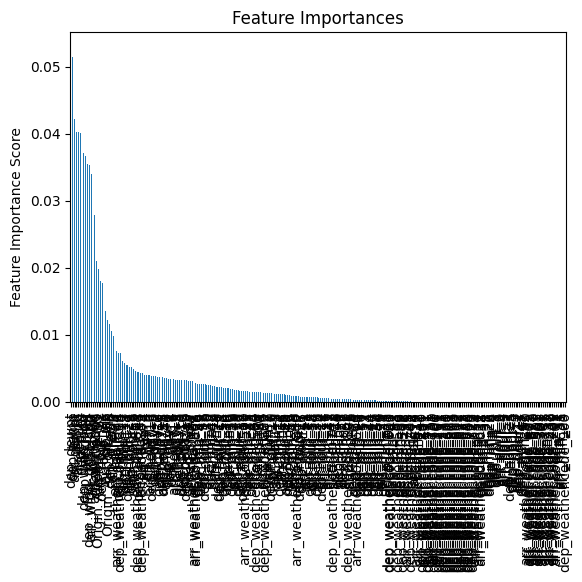

<Figure size 2000x1000 with 0 Axes>

In [172]:
rf = RandomForestClassifier(random_state=50, min_samples_leaf = 6, max_features = "sqrt", n_estimators = 100)

rf = rf.fit(X_train, y_train) 
rf.score(X_train, y_train) 

# rf.feature_importances_
feat_imp = pd.Series(rf.feature_importances_, X_train.columns.values).sort_values(ascending=False)

feat_imp_table = pd.DataFrame(feat_imp)
feat_imp_table = feat_imp_table.reset_index()
feat_imp_table.columns = ['Features', 'Values']
feat_imp.plot(kind='bar', title='Feature Importances')
plt.ylabel('Feature Importance Score')
plt.figure(figsize=[40,20], dpi = 50)
feat_imp.head(12)

test_output = pd.DataFrame(rf.predict(X_test), index = X_test.index, columns = ['pred_Y'])

test_output.head()
test_output = test_output.merge(y_test, left_index = True, right_index = True)
test_output.head()
print('Fraction of correct classification ')
rf.score(X_test, y_test) 

In [173]:
gb = GradientBoostingClassifier(random_state=50, min_samples_split = 12, min_samples_leaf = 6, max_depth = 4, n_estimators = 300)

gb = gb.fit(X_train, y_train) 
gb.score(X_train, y_train) 

0.8342071958054601

In [174]:
linear_reg_output = pd.DataFrame(gb.predict(X_test), index = X_test.index, columns = ['pred_arr_status'])
linear_reg_output = linear_reg_output.merge(y_test, left_index = True, right_index = True)
linear_reg_output.head(20)
gb.score(X_test,y_test)

,pred_arr_status,arr_status
1142,0,0
124,0,0
5294,0,1
2482,0,0
3820,0,0
2177,0,0
5348,0,0
2492,0,0
4828,0,1
569,2,2


0.5459146782357195

In [175]:
pred_data1 = pd.read_csv('pred_data1.csv')
pred_data1.head()
pred_data1.dtypes

,Unnamed: 0,dep_hour,dep_day,Origin_Airport,arr_hour,arr_day,dep_min,arr_min,arr_clouds,arr_dewpt,...,dep_precip,dep_pres,dep_rh,dep_snow,dep_temp,dep_vis,dep_weather.code,dep_wind_dir,dep_wind_gust_spd,dep_wind_spd
0,0,18,4,ORD,21,4,52,47,69,8.00,...,0.00,996.50,35,0,12.70,24.00,801,280,12.50,8.40
1,2,13,4,JFK,14,4,34,51,84,7.20,...,0.00,"1,019.50",58,0,12.10,24.00,804,110,7.20,5.20
2,4,11,4,MCO,14,4,35,20,84,7.20,...,0.00,"1,015.00",58,0,28.10,24.00,801,280,2.40,2.00
3,6,18,5,ORD,21,5,52,47,23,-2.40,...,0.00,994.00,40,0,9.70,24.13,803,296,6.66,4.40
4,8,13,5,JFK,14,5,25,41,71,-1.20,...,0.00,"1,014.50",46,0,15.80,24.00,803,283,5.73,4.13


Unnamed: 0             int64
dep_hour               int64
dep_day                int64
Origin_Airport        object
arr_hour               int64
arr_day                int64
dep_min                int64
arr_min                int64
arr_clouds             int64
arr_dewpt            float64
arr_precip           float64
arr_pres             float64
arr_rh                 int64
arr_snow               int64
arr_temp             float64
arr_vis              float64
arr_weather.code       int64
arr_wind_dir           int64
arr_wind_gust_spd    float64
arr_wind_spd         float64
dep_clouds             int64
dep_dewpt            float64
dep_precip           float64
dep_pres             float64
dep_rh                 int64
dep_snow               int64
dep_temp             float64
dep_vis              float64
dep_weather.code       int64
dep_wind_dir           int64
dep_wind_gust_spd    float64
dep_wind_spd         float64
dtype: object

In [176]:

pred_data1['dep_min'] = pred_data1['dep_min'].astype('object')
pred_data1['arr_min'] = pred_data1['arr_min'].astype('object')
pred_data1['dep_hour'] = pred_data1['dep_hour'].astype('object')
pred_data1['dep_day'] = pred_data1['dep_day'].astype('object')
pred_data1['arr_hour'] = pred_data1['arr_hour'].astype('object')
pred_data1['arr_day'] = pred_data1['arr_day'].astype('object')
pred_data1['dep_weather.code'] = pred_data1['dep_weather.code'].astype('object')
pred_data1['arr_weather.code'] = pred_data1['arr_weather.code'].astype('object')
pred_data1.drop(columns=['Unnamed: 0'],inplace=True)
pred_data1 = pred_data1[['dep_hour', 'dep_day', 'Origin_Airport', 'arr_hour', 'arr_day',
       'dep_min', 'arr_min', 'arr_clouds', 'arr_dewpt',
       'arr_precip', 'arr_pres', 'arr_rh', 'arr_snow', 'arr_temp', 'arr_vis',
       'arr_weather.code', 'arr_wind_dir', 'arr_wind_gust_spd', 'arr_wind_spd',
       'dep_clouds', 'dep_dewpt', 'dep_precip', 'dep_pres', 'dep_rh',
       'dep_snow', 'dep_temp', 'dep_vis', 'dep_weather.code', 'dep_wind_dir',
       'dep_wind_gust_spd', 'dep_wind_spd']]

pred_data1.dtypes

dep_hour              object
dep_day               object
Origin_Airport        object
arr_hour              object
arr_day               object
dep_min               object
arr_min               object
arr_clouds             int64
arr_dewpt            float64
arr_precip           float64
arr_pres             float64
arr_rh                 int64
arr_snow               int64
arr_temp             float64
arr_vis              float64
arr_weather.code      object
arr_wind_dir           int64
arr_wind_gust_spd    float64
arr_wind_spd         float64
dep_clouds             int64
dep_dewpt            float64
dep_precip           float64
dep_pres             float64
dep_rh                 int64
dep_snow               int64
dep_temp             float64
dep_vis              float64
dep_weather.code      object
dep_wind_dir           int64
dep_wind_gust_spd    float64
dep_wind_spd         float64
dtype: object

In [177]:
pred_data1['dep_hour'] = pd.Categorical(pred_data1['dep_hour'], categories=[i for i in range(24)])
pred_data1['dep_day'] = pd.Categorical(pred_data1['dep_day'], categories=[i for i in range(7)])
pred_data1['dep_min'] = pd.Categorical(pred_data1['dep_min'], categories=[i for i in range(60)])
pred_data1['arr_hour'] = pd.Categorical(pred_data1['arr_hour'], categories=[i for i in range(24)])
pred_data1['arr_day'] = pd.Categorical(pred_data1['arr_day'], categories=[i for i in range(7)])
pred_data1['arr_min'] = pd.Categorical(pred_data1['arr_min'], categories=[i for i in range(60)])
#su_data['Carrier_Code'] = pd.Categorical(su_data['Carrier_Code'], categories=['AA', 'UA', 'DL', 'B6', 'WN'])
pred_data1['Origin_Airport'] = pd.Categorical(pred_data1['Origin_Airport'], categories=['ORD', 'JFK', 'MCO'])
pred_data1['arr_weather.code'] = pd.Categorical(pred_data1['arr_weather.code'], categories=[200,201,202,230,231,232,233,300,301,302,500,501,502,511,520,522,600,602,610,611,612,621,622,633,700,711,721,731,741,751,800,801,802,803,804,900])
pred_data1['dep_weather.code'] = pd.Categorical(pred_data1['dep_weather.code'], categories=[200,201,202,230,231,232,233,300,301,302,500,501,502,511,520,522,600,602,610,611,612,621,622,633,700,711,721,731,741,751,800,801,802,803,804,900])



In [178]:
pred_data1 = pd.get_dummies(pred_data1, drop_first = True)
#su_data['arr_status'] = su_data['arr_status'].astype('object')
pred_data1.head()
pred_data1.dtypes
pred_data1.columns

,arr_clouds,arr_dewpt,arr_precip,arr_pres,arr_rh,arr_snow,arr_temp,arr_vis,arr_wind_dir,arr_wind_gust_spd,...,dep_weather.code_721,dep_weather.code_731,dep_weather.code_741,dep_weather.code_751,dep_weather.code_800,dep_weather.code_801,dep_weather.code_802,dep_weather.code_803,dep_weather.code_804,dep_weather.code_900
0,69,8.00,0.50,999.00,73,0,12.70,19.20,260,8.30,...,False,False,False,False,False,True,False,False,False,False
1,84,7.20,0.50,996.50,55,0,16.30,22.00,160,13.70,...,False,False,False,False,False,False,False,False,True,False
2,84,7.20,0.50,996.50,55,0,16.30,22.00,160,13.70,...,False,False,False,False,False,True,False,False,False,False
3,23,-2.40,0.00,998.50,53,0,6.50,24.13,276,8.53,...,False,False,False,False,False,False,False,True,False,False
4,71,-1.20,0.00,"1,000.50",44,0,10.50,20.40,290,11.20,...,False,False,False,False,False,False,False,True,False,False


arr_clouds                int64
arr_dewpt               float64
arr_precip              float64
arr_pres                float64
arr_rh                    int64
                         ...   
dep_weather.code_801       bool
dep_weather.code_802       bool
dep_weather.code_803       bool
dep_weather.code_804       bool
dep_weather.code_900       bool
Length: 270, dtype: object

Index(['arr_clouds', 'arr_dewpt', 'arr_precip', 'arr_pres', 'arr_rh',
       'arr_snow', 'arr_temp', 'arr_vis', 'arr_wind_dir', 'arr_wind_gust_spd',
       ...
       'dep_weather.code_721', 'dep_weather.code_731', 'dep_weather.code_741',
       'dep_weather.code_751', 'dep_weather.code_800', 'dep_weather.code_801',
       'dep_weather.code_802', 'dep_weather.code_803', 'dep_weather.code_804',
       'dep_weather.code_900'],
      dtype='object', length=270)

In [179]:
from sklearn.preprocessing import StandardScaler
#sc = StandardScaler()
X_test = pd.DataFrame(sc.transform(pred_data1), columns = pred_data1.columns, index = pred_data1.index)


In [180]:
linear_reg_output = pd.DataFrame(model.predict(X_test), index = X_test.index, columns = ['pred_arr_status'])
#linear_reg_output = linear_reg_output.merge(y_test, left_index = True, right_index = True)
linear_reg_output.head(30)
# mean_absolute_error = abs(linear_reg_output['pred_delay'] - linear_reg_output['arr_delay']).mean()
# print('Mean absolute error is ')
# print(mean_absolute_error)
# maer = mean_absolute_error/linear_reg_output['pred_delay'].mean()
# print('Mean absolute error ratio is ')
# print(maer)
#model.score(X_test, y_test)

,pred_arr_status
0,0
1,2
2,1
3,0
4,2
5,0
6,0
7,0
8,0
9,0


In [181]:
pred_data1.head(20)

,arr_clouds,arr_dewpt,arr_precip,arr_pres,arr_rh,arr_snow,arr_temp,arr_vis,arr_wind_dir,arr_wind_gust_spd,...,dep_weather.code_721,dep_weather.code_731,dep_weather.code_741,dep_weather.code_751,dep_weather.code_800,dep_weather.code_801,dep_weather.code_802,dep_weather.code_803,dep_weather.code_804,dep_weather.code_900
0,69,8.00,0.50,999.00,73,0,12.70,19.20,260,8.30,...,False,False,False,False,False,True,False,False,False,False
1,84,7.20,0.50,996.50,55,0,16.30,22.00,160,13.70,...,False,False,False,False,False,False,False,False,True,False
2,84,7.20,0.50,996.50,55,0,16.30,22.00,160,13.70,...,False,False,False,False,False,True,False,False,False,False
3,23,-2.40,0.00,998.50,53,0,6.50,24.13,276,8.53,...,False,False,False,False,False,False,False,True,False,False
4,71,-1.20,0.00,"1,000.50",44,0,10.50,20.40,290,11.20,...,False,False,False,False,False,False,False,True,False,False
5,9,-2.90,0.00,996.50,46,0,8.00,24.13,256,12.83,...,False,False,False,False,False,True,False,False,False,False
6,44,-3.10,0.00,997.50,38,0,10.60,24.13,270,12.30,...,False,False,False,False,False,False,False,True,False,False
7,48,-2.80,0.00,998.00,41,0,9.80,24.13,270,11.80,...,False,False,False,False,False,False,True,False,False,False
8,10,-4.70,0.00,"1,003.00",43,0,7.00,24.13,270,6.54,...,False,False,False,False,False,False,False,False,True,False
9,10,-4.80,0.00,"1,001.50",33,0,10.90,24.13,300,8.50,...,False,False,False,False,False,False,True,False,False,False
